tarea 1:MCMC. Algoritmo de Metropolis
simulacion 2

# se usuaran las siguietnes librerias para resoler el problema

In [2]:
#librerias
import numpy as np
import matplotlib.pyplot as plt

defenimos la funcion objetivo, que se dio en la clase

In [4]:
def f(x1, x2, C=1.0):   #construimos la funcion


    exponente = -(x1**2 + x2**2 + x1**2 + x2**2 - 8*x1 - 8*x2) / 2 # escribimos aqui la funcion objerivo

    return C * np.exp(exponente)

construimos la malla

In [6]:
x1 = np.linspace(-3, 5, 300)    #construimnos los puntos fijos para x1 y x2
x2 = np.linspace(-3, 5, 300)

X1, X2 = np.meshgrid(x1, x2)

Z = f(X1, X2)

creamos la grafica en 3d

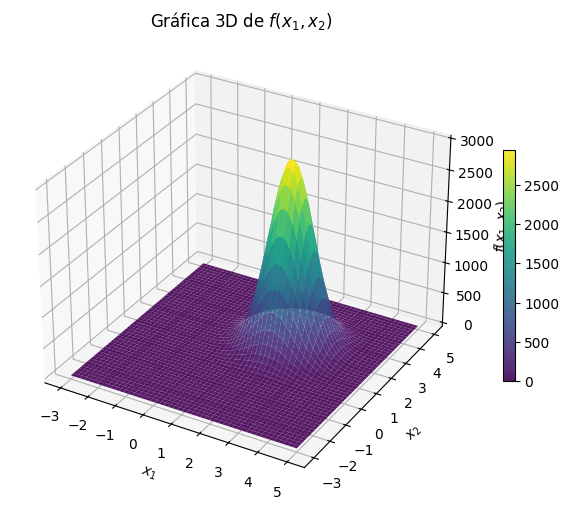

In [8]:
fig = plt.figure(figsize=(8, 6)) #indicamos el tamaño de la figura

ax = fig.add_subplot(111, projection="3d") #agregamos un sistema de ejes a la figura

superficie = ax.plot_surface(      #dibuajmos la superfice en 3d
    X1,
    X2,
    Z,
    cmap="viridis",
    edgecolor="none",
    alpha=0.9
)

ax.set_title(r"Gráfica 3D de $f(x_1,x_2)$") # le damos los nombres a la grafica el titulo y los ejes
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_zlabel(r"$f(x_1,x_2)$")

fig.colorbar(superficie, ax=ax, shrink=0.5)

plt.show()

constuimos el mapa de contornos

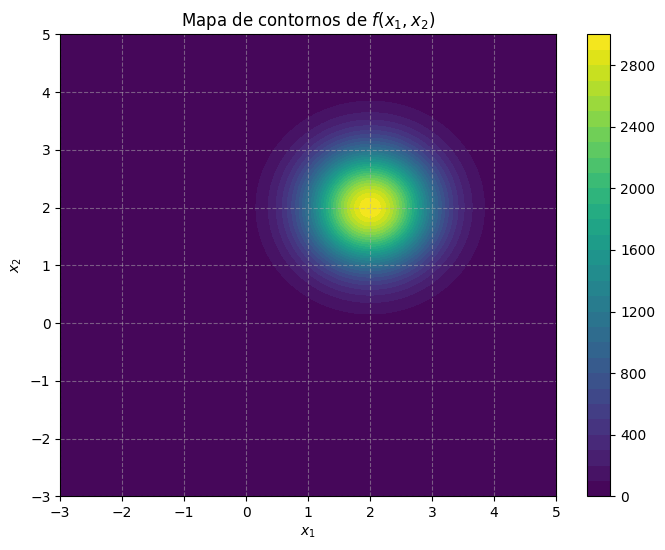

In [9]:
plt.figure(figsize=(8, 6)) #le damos el tamaño del mapa de contornos

contorno = plt.contourf(     #dibuja el mapa de contorno
    X1,  #cordenada del eje x
    X2,  #cordenada del eje y
    Z,      # valores de la funcion z
    levels=30,   # se devide los valores de z en 30 niveles
    cmap="viridis"
)

plt.colorbar(contorno) # agrega la barra de colores

plt.title(r"Mapa de contornos de $f(x_1,x_2)$")
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")

plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

construimos el algoritmo de metropolis.
variables que vamos usar:
  
    Implementación del algoritmo de Metropolis.

    Parámetros:
    f              -> función objetivo
    x_inicial      -> punto inicial [x1, x2]
    n_iteraciones  -> número de iteraciones
    sigma          -> desviación estándar de la propuesta

    Devuelve:
    muestras       -> puntos generados por Metropolis
    tasa_aceptacion -> porcentaje de propuestas aceptadas
    

In [11]:
def metropolis(f, x_inicial, n_iteraciones, sigma):


    # constyruimos la matriz en donde vamos a guardar las muesrtras
    muestras = np.zeros((n_iteraciones, 2))

    # Punto inicial
    x_actual = np.array(x_inicial, dtype=float)

    # Contador de movimientos aceptados
    aceptadas = 0

    for i in range(n_iteraciones):


        # proponemos un nuevo punto


        propuesta = x_actual + np.random.normal(
            loc=0,
            scale=sigma,
            size=2
        )


        # evaluamos la funcion


        f_actual = f(x_actual[0], x_actual[1])

        f_propuesta = f(propuesta[0], propuesta[1])


        # calculamos la probabilidad de aceptacion


        if f_actual == 0:
            alpha = 1.0
        else:
            alpha = min(
                1.0,
                f_propuesta / f_actual
            )


        #  generamos un numero uniforme u(0,1)


        u = np.random.uniform(0, 1)


        # hacemos un if para saber si aceptamos o rechazamos


        if u <= alpha:

            x_actual = propuesta

            aceptadas += 1

        # guardamos el estado de la cadena
        muestras[i] = x_actual

    # calculamos la tasa de aceptacion
    tasa_aceptacion = aceptadas / n_iteraciones

    return muestras, tasa_aceptacion

ejecutamos metropolis

In [12]:
# construimos la semilla para reproducir los resultados
np.random.seed(123)

# Punto inicial
x_inicial = [0, 0]

# Número de iteraciones
n_iteraciones = 20000

# Desviación estándar de la propuesta
sigma = 1.0


muestras, tasa = metropolis(
    f,
    x_inicial,
    n_iteraciones,
    sigma
)


print("Número de iteraciones:", n_iteraciones)

print(
    "Tasa de aceptación:",
    round(tasa * 100, 2),
    "%"
)

Número de iteraciones: 20000
Tasa de aceptación: 42.53 %


el resultado que tuvimos fue una tasa de aceptacion de 42.53%

In [13]:
# Eliminamos las primeras muestras porque la cadena puede
# depender demasiado del punto inicial.

burn_in = 2000

muestras_finales = muestras[burn_in:]


print("Muestras totales:", len(muestras))

print(
    "Muestras después del burn-in:",
    len(muestras_finales)
)

Muestras totales: 20000
Muestras después del burn-in: 18000


graficamos la muestra

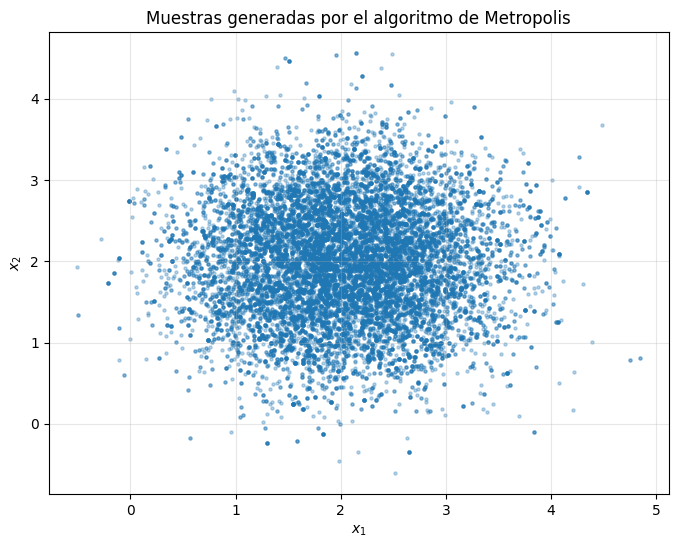

In [14]:
plt.figure(figsize=(8, 6)) #tamaño de la grafica

plt.scatter( #creamos la grafica de dispersion
    muestras_finales[:, 0],
    muestras_finales[:, 1],
    s=5,
    alpha=0.3
)

plt.title("Muestras generadas por el algoritmo de Metropolis")

plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")

plt.grid(alpha=0.3)

plt.show()

graficamos la muestras sobre el contorno

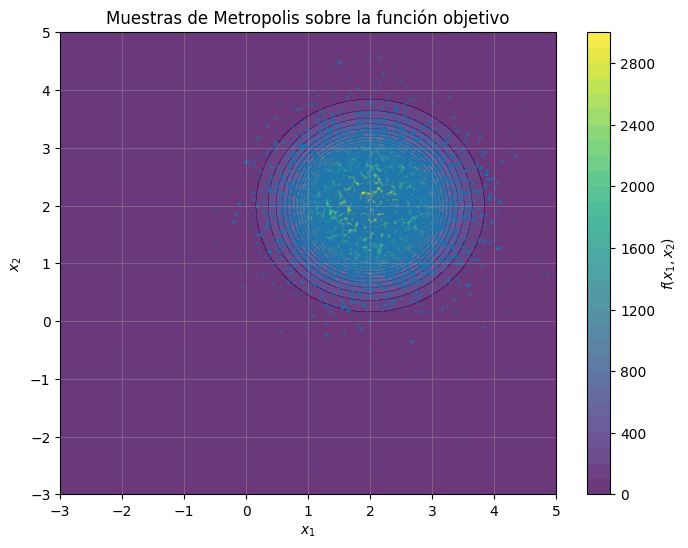

In [15]:
plt.figure(figsize=(8, 6)) # tamaño de la figura

plt.contourf(
    X1,
    X2,
    Z,
    levels=30,
    cmap="viridis",
    alpha=0.8
)

plt.colorbar( # añadimos la escala de colores
    label=r"$f(x_1,x_2)$"
)

plt.scatter( #dibujamos la muestra de metropolis
    muestras_finales[:, 0],
    muestras_finales[:, 1],
    s=3,
    alpha=0.15
)

plt.title(
    "Muestras de Metropolis sobre la función objetivo"
)

plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")

plt.grid(alpha=0.3)

plt.show()

graficamos la evolucion de la cadena

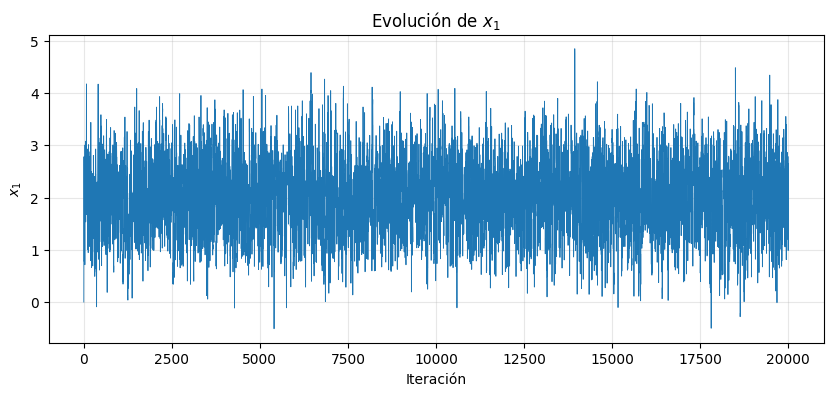

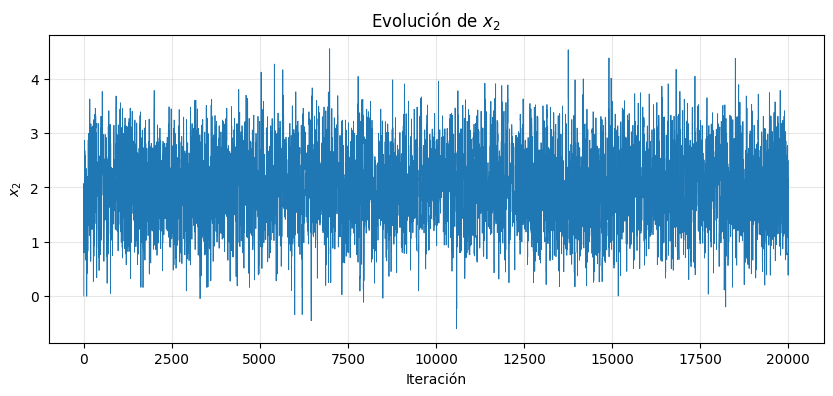

In [16]:
plt.figure(figsize=(10, 4)) #tamaño de la grafica

plt.plot( #construimos la grafica de la serie de tiempo
    muestras[:, 0],
    linewidth=0.6
)

plt.title(r"Evolución de $x_1$")

plt.xlabel("Iteración")
plt.ylabel(r"$x_1$")

plt.grid(alpha=0.3)

plt.show()


plt.figure(figsize=(10, 4)) #tamaño de la grafica de x2

plt.plot(   #construimos la serie de tiempo de x2
    muestras[:, 1],
    linewidth=0.6
)

plt.title(r"Evolución de $x_2$")

plt.xlabel("Iteración")
plt.ylabel(r"$x_2$")

plt.grid(alpha=0.3)

plt.show()

construimos los histogramas de x1 y x2

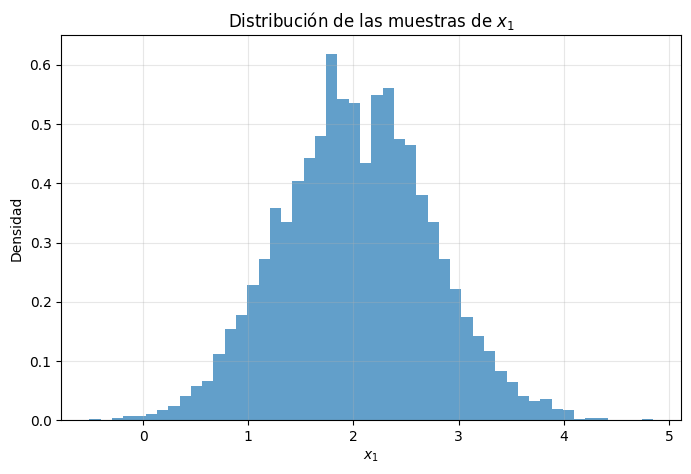

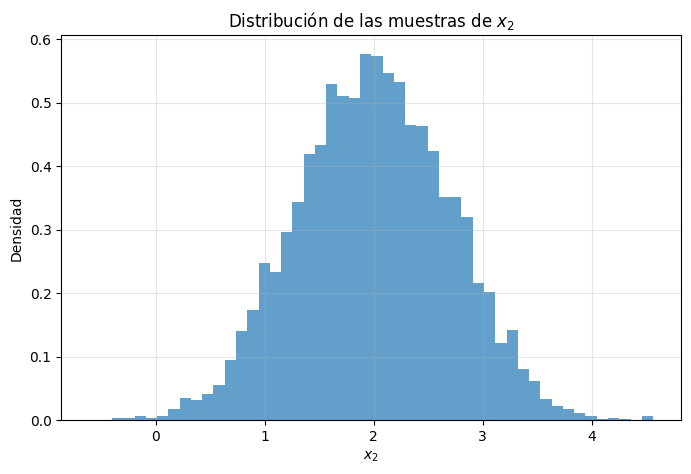

In [17]:
plt.figure(figsize=(8, 5)) #tamaño de la figura

plt.hist( #construimos el histograma para x1
    muestras_finales[:, 0],
    bins=50,
    density=True,
    alpha=0.7
)

plt.title(r"Distribución de las muestras de $x_1$")

plt.xlabel(r"$x_1$")
plt.ylabel("Densidad")

plt.grid(alpha=0.3)

plt.show()


plt.figure(figsize=(8, 5)) #tamaño de la figura de x2

plt.hist( #construimnos el histograma para x2
    muestras_finales[:, 1],
    bins=50,
    density=True,
    alpha=0.7
)

plt.title(r"Distribución de las muestras de $x_2$")

plt.xlabel(r"$x_2$")
plt.ylabel("Densidad")

plt.grid(alpha=0.3)

plt.show()

resultados estadisticos que obtuvimos

In [18]:
media_x1 = np.mean(muestras_finales[:, 0]) #media x1

media_x2 = np.mean(muestras_finales[:, 1]) #media x2

desviacion_x1 = np.std(muestras_finales[:, 0]) #desviacion de x1

desviacion_x2 = np.std(muestras_finales[:, 1]) #desviacion de x2


print("\n----- RESULTADOS FINALES -----") #imprimimos los reusltados finales que se obtuvo

print(
    "Media de x1:",
    round(media_x1, 4)
)

print(
    "Media de x2:",
    round(media_x2, 4)
)

print(
    "Desviación estándar de x1:",
    round(desviacion_x1, 4)
)

print(
    "Desviación estándar de x2:",
    round(desviacion_x2, 4)
)

print(
    "Tasa de aceptación:",
    round(tasa * 100, 2),
    "%"
)


----- RESULTADOS FINALES -----
Media de x1: 2.026
Media de x2: 2.0018
Desviación estándar de x1: 0.7123
Desviación estándar de x2: 0.6972
Tasa de aceptación: 42.53 %


se obtuvo una media de x1=2.026 y una media de x2=2.0018.
se obtuvieron los valores de la desviacion de x1=0.7123 y  x2=0.6972.
tuvimos la tasa de aceptacion de 42.53%.